Вот датасет: https://www.kaggle.com/competitions/GiveMeSomeCredit/data

По пунктам:
1) Проводишь EDA train датасета
2) Экспериментируешь и обучаешь модели для прогнозирования признака `SeriousDlqin2yrs`
3) Выбираешь модель, с помощью SHAP выделяешь самые важные фичи (штук 5-6)
4) Обучаешь новую модель исключительно на этих фичах
5) В streamlit пишешь "анкету клиента", где можно будет заполнить значения данных фичей.
6) Создаешь сервер на FastAPI: закидываешь туда веса модели и прописываешь запрос для прогона входных значений в модели и отправки результата обратно клиенту
7) Связываешь frontend и backend, в веб-страничке клиента должен отобразится результат работы модели: прогнозируем ли мы дефолт для клиента или нет

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
import duckdb
import joblib
from cycler import cycler
#ml preproc
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import (
    train_test_split,
    KFold
)
import optuna
import shap
#ml models
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
#metrics
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    f1_score,
    roc_auc_score, 
    average_precision_score,
    recall_score,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

Импорт библиотек

In [2]:
warnings.filterwarnings('ignore')

RANDOM_STATE = 42
VAL_SIZE = 0.15

colormap = sns.diverging_palette(220, 10, as_cmap=True)
colorbox = [
    "#fb4934",  # Красный
    "#fabd2f",  # Желтый
    "#b8bb26",  # Зеленый
    "#83a598",  # Голубой
    "#d3869b",  # Фиолетовый
    "#fe8019",  # Ораньжевый
    "#8ec07c",  # Бирюзовый
]

rc = {
    "axes.facecolor": "#282828",
    "figure.facecolor": "#282828",
    "axes.edgecolor": "#3c3836",
    "grid.color": "#504945",
    "axes.labelcolor": "#ebdbb2",
    "xtick.color": "#d5c4a1",
    "ytick.color": "#d5c4a1",
    "grid.alpha": 0.3,
    "axes.prop_cycle": cycler(color=colorbox),
    "legend.facecolor": "#DCDCDC",
    "text.color": "ebdbb2", 
    "axes.titlecolor": "white",
    "xtick.color": "white",
    "ytick.color": "white",
    "legend.labelcolor": "white",
    "legend.title_fontsize": 12,
}

sns.set(rc=rc, style="darkgrid")
# Устанавливаем настройку rc и стиль "darkgrid" seaborn

Константы и настройка

In [3]:
#Функция для визуализации EDA графиков: гистограмма, boxplot
def num_plot(data,column_list,bins=50,figsize=(6,3),target=None,kde=True):
    for column in column_list:
        plt.figure(figsize=(figsize))
        # Первый subplot - ГИСТОГРАММА
        plt.subplot(1,2,1)
        sns.histplot(data=data,x=column,kde=kde,bins=bins, palette=colorbox, alpha=0.5, hue=target)
        plt.title(f'Гистограмма частоты {column}',color='white')
        plt.xlabel(f'Значения {column}',color='white')
        plt.ylabel('Частота',color='white')
        plt.grid()
        # Второй subplot - BOXPLOT
        plt.subplot(1,2,2)
        sns.boxplot(data=data,y=column, palette=colorbox, hue=target)
        plt.title(f'Boxplot {column}',color='white')
        plt.xlabel('Boxplot',color='white')
        plt.ylabel('Значения',color='white')
        plt.grid()
        plt.show()

#Функция визуализации pie charm
def pie_charm(series,title='',colors=[colorbox[0],colorbox[1]]):
    vc_series = series.value_counts()
    values = vc_series.values
    index = list(vc_series.index)
    plt.figure(figsize=(14, 7))
    plt.pie(
        values,
        labels=index,
        startangle=90, frame=True, radius=1.3,
        wedgeprops={'linewidth': 1, 'edgecolor': 'white'},
        textprops={'fontsize': 12, 'weight': 'bold'},
        autopct='%1.1f%%',
        colors=colors,
    )
    plt.legend()
    plt.title(title,color='white')
    plt.show()

#Функция для визуализации EDA графиков: countplot
def count_plot(data,column_list,figsize=(9,3),palette=colorbox, rotation=90, xfontsize=10):
    for column in column_list:
        plt.figure(figsize=figsize)
        sns.countplot(data=data,x=column,palette=colorbox)
        plt.title(f'Количество {column}',color='white')
        plt.xlabel('Значения',color='white')
        plt.ylabel('Количество значений',color='white')
        plt.xticks(fontsize=xfontsize,rotation=rotation)
        plt.show()

#Функция визуализации линейной зависимости
def plotlm(data, x_var, y_var, row_var=None, target=None):
    plt.figure(figsize=(14,7))
    lm = sns.lmplot(
        data=data,
        x=x_var,
        y=y_var,
        row=row_var,
        hue = row_var,
        lowess=True,
        height=2,
        aspect=4,
        palette=palette_sex ,
        col=target,
        line_kws={"color": "white"},
        scatter_kws={"alpha": 0.3},
    )
    for ax in lm.axes.flatten():
        ax.tick_params(color='white')
        ax.xaxis.label.set_color("white")
        ax.yaxis.label.set_color("white")

        lm.set_titles(
            col_template="Target value:{col_name}",
            color="white",
            size=12,
            weight="bold"
    )
    plt.suptitle(
        f"{x_var.replace('_', ' ').title()} VS {y_var.replace('_', ' ').title()} by Target Variable",
        y=1.02,
        fontsize=16,color='white',
    )
    plt.tight_layout()
    plt.show()

#lift метрика
def lift_at_k(y_true, y_proba, k=0.1):
    n = len(y_true)
    top_k_idx = np.argsort(y_proba)[::-1][:int(n * k)]
    return pd.Series(y_true).iloc[top_k_idx].mean() / pd.Series(y_true).mean()

#Метрики для быстрой оценки качества
def model_metrics(y_true, y_pred, y_proba):
    roc = roc_auc_score(y_true, y_proba)
    pr = average_precision_score(y_true, y_proba)
    gini = 2 * roc - 1
    lift10 = lift_at_k(y_true, y_proba, 0.1)
    lift20 = lift_at_k(y_true, y_proba, 0.2)
    print(f'ROC-AUC : {roc:.4f}')
    print(f'PR-AUC  : {pr:.4f}')
    print(f'Gini    : {gini:.4f}')
    print(f'Lift@10 : {lift10:.4f}')
    print(f'Lift@20 : {lift20:.4f}')
    print(f'Recall  : {recall_score(y_true, y_pred):.4f}')
    print(f'Precision  : {precision_score(y_true, y_pred):.4f}')
    print(f'F1  : {f1_score(y_true, y_pred):.4f}')
    print(f'Accuracy  : {accuracy_score(y_true, y_pred):.4f}')

#Подбор порога
def threshold_report(y_true, y_proba, thresholds=(0.5, 0.4, 0.3, 0.2, 0.1)):
    print(f'{"Threshold":<10} {"F1":<10} {"Recall":<10} {"Precision":<10}')

    for t in thresholds:
        y_pred = (y_proba >= t).astype(int)

        print(f'{t:<10.2f}'
              f'{f1_score(y_true, y_pred):<10.3f}'
              f'{recall_score(y_true, y_pred):<10.3f}'
              f'{precision_score(y_true, y_pred, zero_division=0):<10.3f}')

Функции

In [4]:
df_train = pd.read_csv("datasets/GMSC/cs-training.csv")
df_test = pd.read_csv("datasets/GMSC/cs-test.csv")

Загрузка датасетов:


#### _____ **Variable Name** _______________________ **Description** _____________________________________________________________________ **Type**

* **SeriousDlqin2yrs** - Была ли у человека просрочка на 90+ дней или хуже за последние 2 года	***integer (Y/N)***

* **RevolvingUtilizationOfUnsecuredLines** - Отношение общего баланса по кредитным картам и персональным кредитным линиям
(кроме недвижимости и автокредитов) к сумме кредитных лимитов	***float (percentage)***

* **age** - Возраст заёмщика ***integer***

* **NumberOfTime30-59DaysPastDueNotWorse** - Количество случаев, когда заёмщик имел просрочку 30–59 дней (не хуже) за последние 2 года ***integer***

* **DebtRatio** - Отношение ежемесячных платежей по долгам, алиментов и расходов на жизнь к ежемесячному валовому доходу	***float (percentage)***

* **MonthlyIncome** - Ежемесячный доход	***integer***

* **NumberOfOpenCreditLinesAndLoans** - Количество открытых кредитов (например, автокредит, ипотека) и кредитных линий (например, кредитные карты)	***integer***

* **NumberOfTimes90DaysLate** - Количество случаев просрочки на 90+ дней ***integer***

* **NumberRealEstateLoansOrLines** - Количество ипотечных кредитов и кредитов под недвижимость, включая кредитные линии под залог жилья ***integer***


* **NumberOfTime60-89DaysPastDueNotWorse** - Количество случаев, когда заёмщик имел просрочку 60–89 дней (не хуже) за последние 2 года ***integer***


* **NumberOfDependents** - Количество иждивенцев в семье (не включая самого заёмщика): супруг(а), дети и т.д.	***integer***

In [5]:
df_train.head()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [6]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 12 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   Unnamed: 0                            150000 non-null  int64  
 1   SeriousDlqin2yrs                      150000 non-null  int64  
 2   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 3   age                                   150000 non-null  int64  
 4   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 5   DebtRatio                             150000 non-null  float64
 6   MonthlyIncome                         120269 non-null  float64
 7   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 8   NumberOfTimes90DaysLate               150000 non-null  int64  
 9   NumberRealEstateLoansOrLines          150000 non-null  int64  
 10  NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 11  

In [7]:
df_test.head()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,NaN,0.885519,43,0,0.177513,5700.0,4,0,0,0,0.0
1,2,NaN,0.463295,57,0,0.527237,9141.0,15,0,4,0,2.0
2,3,NaN,0.043275,59,0,0.687648,5083.0,12,0,1,0,2.0
3,4,NaN,0.280308,38,1,0.925961,3200.0,7,0,2,0,0.0
4,5,NaN,1.000000,27,0,0.019917,3865.0,4,0,0,0,1.0


In [8]:
df_test.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101503 entries, 0 to 101502
Data columns (total 12 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   Unnamed: 0                            101503 non-null  int64  
 1   SeriousDlqin2yrs                      0 non-null       float64
 2   RevolvingUtilizationOfUnsecuredLines  101503 non-null  float64
 3   age                                   101503 non-null  int64  
 4   NumberOfTime30-59DaysPastDueNotWorse  101503 non-null  int64  
 5   DebtRatio                             101503 non-null  float64
 6   MonthlyIncome                         81400 non-null   float64
 7   NumberOfOpenCreditLinesAndLoans       101503 non-null  int64  
 8   NumberOfTimes90DaysLate               101503 non-null  int64  
 9   NumberRealEstateLoansOrLines          101503 non-null  int64  
 10  NumberOfTime60-89DaysPastDueNotWorse  101503 non-null  int64  
 11  

In [9]:
df_train_proc = df_train.drop('Unnamed: 0', axis=1).copy()
df_test_proc = df_test.drop(['SeriousDlqin2yrs','Unnamed: 0'], axis=1).copy()

создаю копии датасетов

<h1 align='center'>EDA</h1>

#### SeriousDlqin2yrs (class balance)

In [10]:
pie_charm(df_train_proc['SeriousDlqin2yrs'], title='Соотношение классов целевой переменной')

<Figure size 1400x700 with 1 Axes>

Датасет сильно несбалансирован: 93.3% клиентов не имели серьёзных просрочек (класс 0), только 6.7% помечены как дефолт (класс 1). Это типичная картина для кредитного скоринга. При обучении моделей необходима компенсация дисбаланса.

#### RevolvingUtilizationOfUnsecuredLines

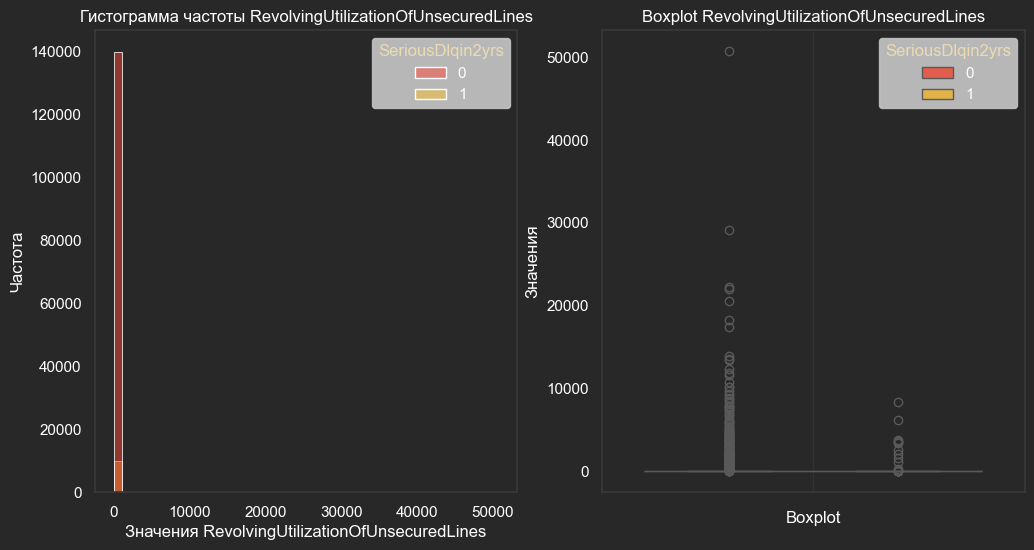

count    150000.000000
mean          6.048438
std         249.755371
min           0.000000
25%           0.029867
50%           0.154181
75%           0.559046
max       50708.000000
Name: RevolvingUtilizationOfUnsecuredLines, dtype: float64

In [11]:
num_plot(df_train_proc, ['RevolvingUtilizationOfUnsecuredLines'], figsize=(12,6), target='SeriousDlqin2yrs', kde=False)
df_train_proc['RevolvingUtilizationOfUnsecuredLines'].describe()

Признак должен быть процентом использования кредитного лимита (0 до 1), но содержит аномальные значения до 50 708 - это явные ошибки данных или специфические случаи (превышение лимита многократно).Медиана 0.154 при среднем 6.05 - экстремальный правый скос целиком из-за выбросов.75% клиентов используют менее 56% лимита (Q3=0.559) - большинство держат кредитную нагрузку в разумных пределах

In [12]:
df_train_proc['util_over_limit'] = (
    df_train_proc['RevolvingUtilizationOfUnsecuredLines'] > 1
).astype(int)

print(df_train_proc.groupby('util_over_limit')['SeriousDlqin2yrs'].agg(['mean','count']))

                     mean   count
util_over_limit                  
0                0.059920  146679
1                0.372478    3321


Лимит превышен лишь у 2% (3321) клиентов в датасете, при этом ~37% из них являются дефолтными.

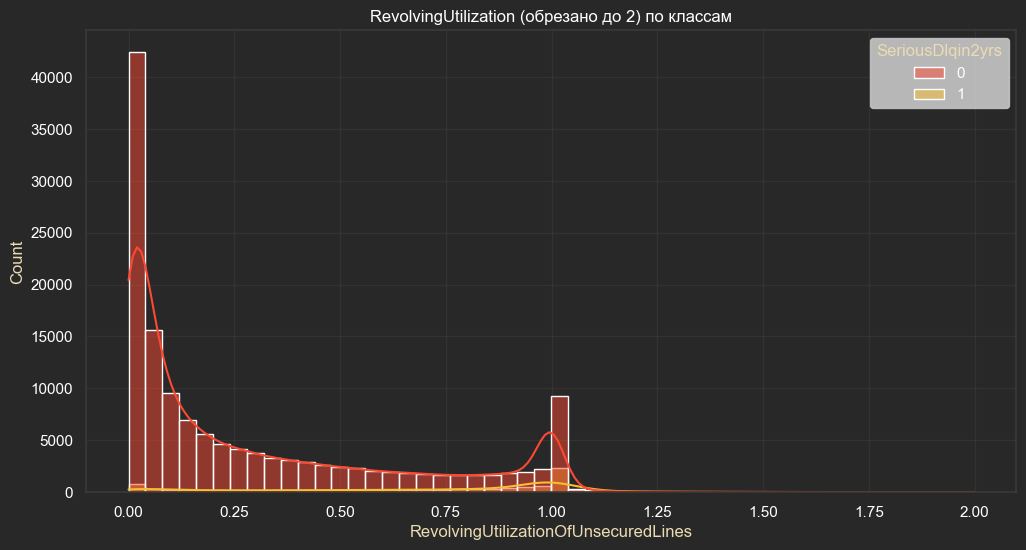

In [13]:
plt.figure(figsize=(12, 6))
sns.histplot(
    data=df_train_proc[df_train_proc['RevolvingUtilizationOfUnsecuredLines'] <= 2],
    x='RevolvingUtilizationOfUnsecuredLines',
    hue='SeriousDlqin2yrs',
    bins=50, 
    kde=True
)
plt.title('RevolvingUtilization (обрезано до 2) по классам')
plt.show()

In [14]:
df_train_proc[df_train_proc['RevolvingUtilizationOfUnsecuredLines']>10].describe()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,util_over_limit
count,241.000000,241.000000,241.000000,241.000000,241.000000,173.00000,241.000000,241.000000,241.000000,241.000000,228.000000,241.0
mean,0.070539,3564.023932,50.630705,0.186722,571.918644,8467.67052,5.763485,0.074689,1.186722,0.087137,0.688596,1.0
std,0.256587,5123.802683,14.565389,0.579502,1772.948412,6564.06825,3.114160,0.579711,1.065750,0.559651,1.038659,0.0
min,0.000000,11.385230,24.000000,0.000000,0.000800,0.00000,1.000000,0.000000,0.000000,0.000000,0.000000,1.0
25%,0.000000,941.000000,39.000000,0.000000,0.217813,4500.00000,4.000000,0.000000,0.000000,0.000000,0.000000,1.0
50%,0.000000,2012.000000,48.000000,0.000000,0.402560,7000.00000,5.000000,0.000000,1.000000,0.000000,0.000000,1.0
75%,0.000000,4116.000000,62.000000,0.000000,59.000000,10091.00000,7.000000,0.000000,2.000000,0.000000,1.000000,1.0
max,1.000000,50708.000000,87.000000,3.000000,21395.000000,44472.00000,21.000000,8.000000,9.000000,7.000000,4.000000,1.0


In [15]:
df_train_proc[df_train_proc['RevolvingUtilizationOfUnsecuredLines']>13].describe()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,util_over_limit
count,238.000000,238.000000,238.000000,238.000000,238.000000,170.000000,238.000000,238.000000,238.000000,238.000000,225.000000,238.0
mean,0.058824,3608.797826,50.634454,0.163866,579.117900,8520.041176,5.689076,0.071429,1.176471,0.071429,0.693333,1.0
std,0.235790,5140.423232,14.617658,0.522123,1782.962163,6606.889618,3.032170,0.580214,1.064558,0.542637,1.043346,0.0
min,0.000000,14.000000,24.000000,0.000000,0.000800,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.0
25%,0.000000,951.000000,39.000000,0.000000,0.216587,4608.000000,4.000000,0.000000,0.000000,0.000000,0.000000,1.0
50%,0.000000,2023.500000,48.000000,0.000000,0.391176,7000.000000,5.000000,0.000000,1.000000,0.000000,0.000000,1.0
75%,0.000000,4128.750000,62.000000,0.000000,82.250000,10178.750000,7.000000,0.000000,2.000000,0.000000,1.000000,1.0
max,1.000000,50708.000000,87.000000,3.000000,21395.000000,44472.000000,21.000000,8.000000,9.000000,7.000000,4.000000,1.0


In [16]:
df_train_proc['RevolvingUtilizationOfUnsecuredLines'] = df_train_proc['RevolvingUtilizationOfUnsecuredLines'].clip(upper=13)
df_train_proc['RevolvingUtilizationOfUnsecuredLines'].describe()

count    150000.000000
mean          0.343106
std           0.625768
min           0.000000
25%           0.029867
50%           0.154181
75%           0.559046
max          13.000000
Name: RevolvingUtilizationOfUnsecuredLines, dtype: float64

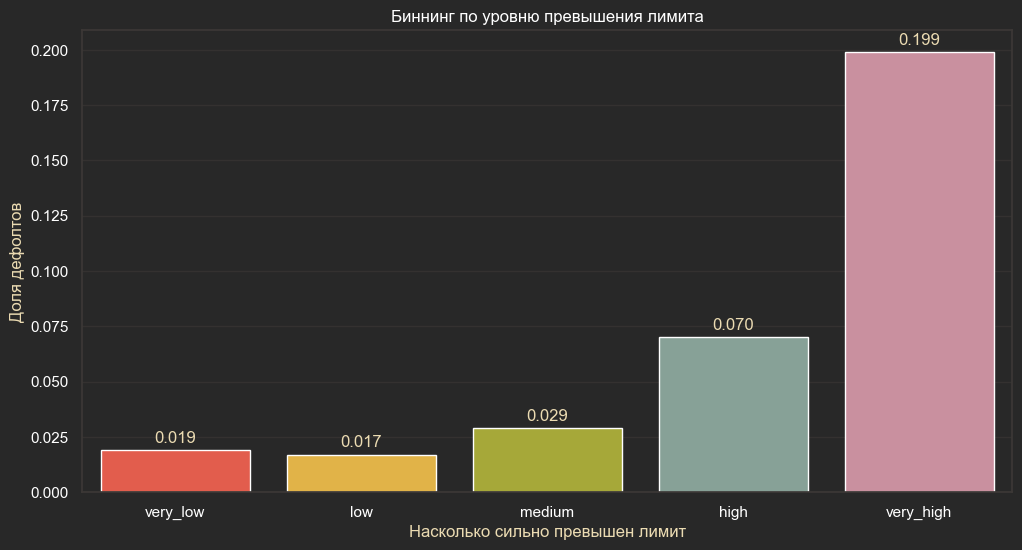

In [17]:
df_train_proc['util_bin'] = pd.qcut(
    df_train_proc['RevolvingUtilizationOfUnsecuredLines'],
    q=5, 
    duplicates='drop',
    labels=['very_low', 'low', 'medium', 'high', 'very_high']
)
plt.figure(figsize=(12, 6))
sns.barplot(
    data=df_train_proc.groupby('util_bin')['SeriousDlqin2yrs'].mean().round(3),
    palette=colorbox
)
for i, v in enumerate(df_train_proc.groupby('util_bin')['SeriousDlqin2yrs'].mean().round(3)):
    plt.text(i,v + 0.002, f'{v:.3f}', ha='center', va='bottom', fontsize=12)
plt.title('Биннинг по уровню превышения лимита')
plt.xlabel('Насколько сильно превышен лимит')
plt.ylabel('Доля дефолтов')
plt.show()

Процент дефолтов по бинам демонстрирует ту же картину: чем сильнее превышены лимиты, тем выше шанс дефолта клиента.

#### Age

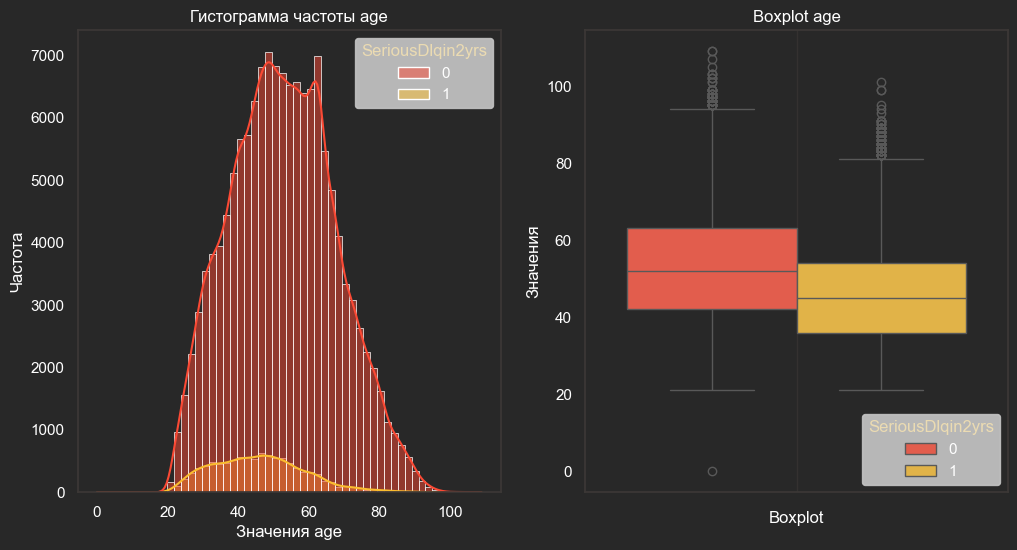

count    150000.000000
mean         52.295207
std          14.771866
min           0.000000
25%          41.000000
50%          52.000000
75%          63.000000
max         109.000000
Name: age, dtype: float64

In [18]:
num_plot(df_train_proc, ['age'], figsize=(12,6), target='SeriousDlqin2yrs', bins=55)
df_train_proc['age'].describe() 

Возраст распределён близко к нормальному с пиком около 45-55 лет, среднее 52.3, медиана 52 - близко, что подтверждает симметричность.Минимум 0 - явная аномалия, возраст не может быть нулевым. Максимум 109 - экстремально высокий, но возможный. Боксплот показывает: клиенты с дефолтом в среднем моложе (Медиана класса 1: 48, медиана класса 2: 52)

In [19]:
print('Нулевой возраст:', (df_train_proc['age'] == 0).sum())
print('Возраст < 18:', (df_train_proc['age'] < 18).sum())

Нулевой возраст: 1
Возраст < 18: 1


Нулевой возраст является единичной ошибкой в данных, все остальные клиенты совершеннолетние.

In [20]:
df_train_proc = df_train_proc.loc[df_train_proc['age'] > 18]

In [21]:
df_train_proc['age_bin'] = pd.cut(
    df_train_proc['age'],
    bins=[0, 25, 35, 45, 55, 65, 110],
    labels=['<25', '25-35', '35-45', '45-55', '55-65', '65+']
)

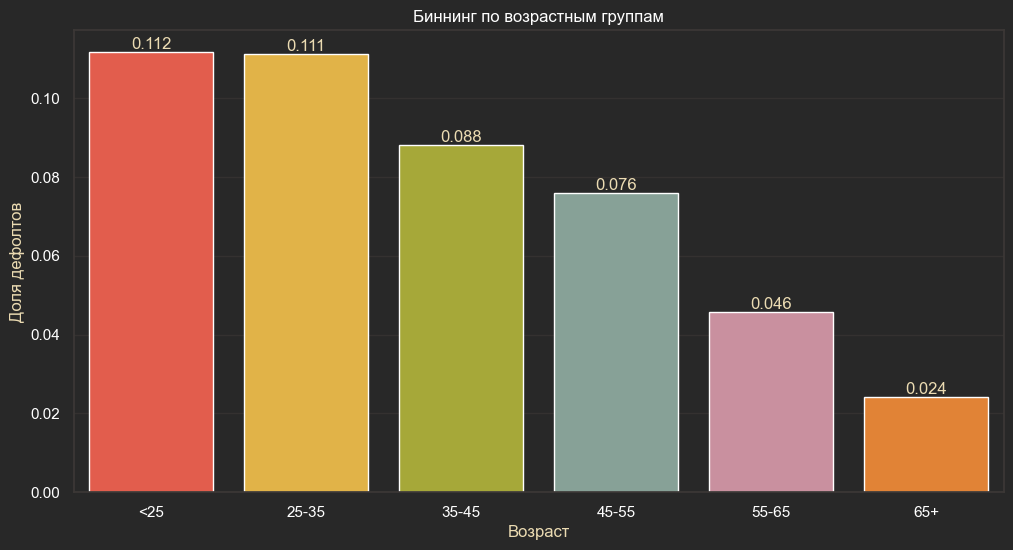

In [22]:
plt.figure(figsize=(12, 6))
sns.barplot(
    data=df_train_proc.groupby('age_bin')['SeriousDlqin2yrs'].mean().reset_index(),
    x='age_bin',
    y='SeriousDlqin2yrs',
    palette=colorbox
)
for i, v in enumerate(df_train_proc.groupby('age_bin')['SeriousDlqin2yrs'].mean()):
    plt.text(i, v, f"{v:.3f}", va='bottom', ha='center', fontsize=12)
plt.title('Биннинг по возрастным группам')
plt.xlabel('Возраст')
plt.ylabel('Доля дефолтов')
plt.show()

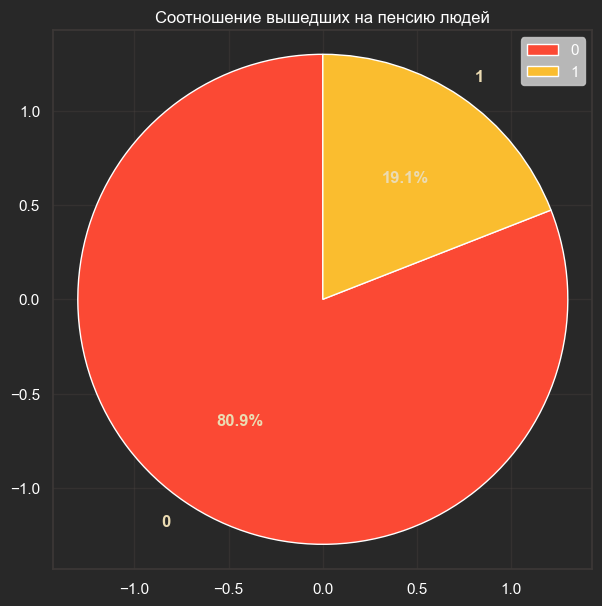

is_retired
0    0.076903
1    0.024127
Name: SeriousDlqin2yrs, dtype: float64

In [23]:
df_train_proc['is_retired'] = (df_train_proc['age'] > 65).astype(int)
pie_charm(df_train_proc['is_retired'], title='Соотношение вышедших на пенсию людей')
df_train_proc.groupby('is_retired')['SeriousDlqin2yrs'].mean()

#### NumberOfTime30-59DaysPastDueNotWorse

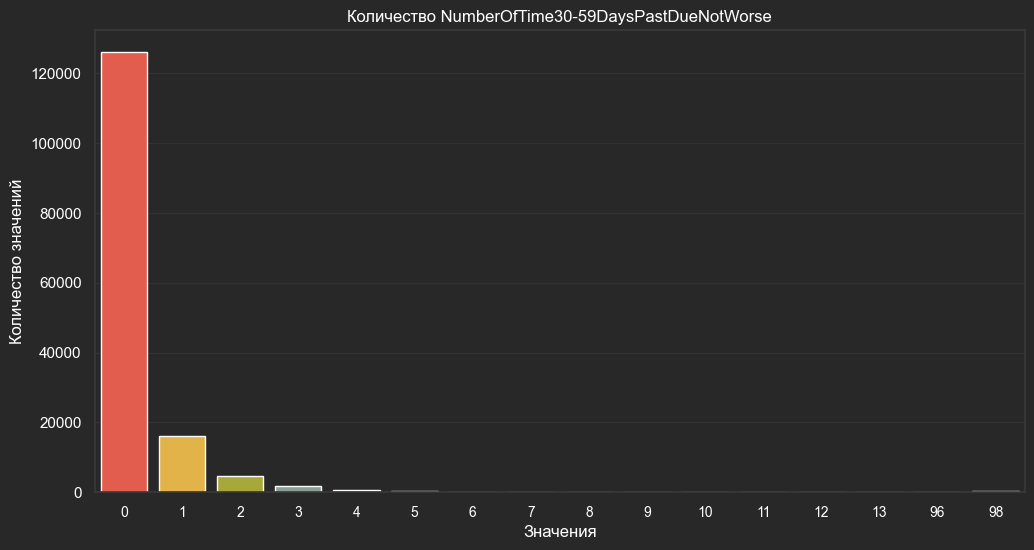

In [24]:
count_plot(df_train_proc, ['NumberOfTime30-59DaysPastDueNotWorse'], figsize=(12,6), rotation=0)

75% клиентов имеют 0 просрочек 30-59 дней - признак сильно сконцентрирован в нуле. Максимальные значения 96 и 98 - почти наверняка ошибка данных или форма записи.

In [25]:
print('Аномальные значения просрочек (+90):')
print(df_train_proc['NumberOfTime30-59DaysPastDueNotWorse'].value_counts().sort_index().tail(5))

Аномальные значения просрочек (+90):
NumberOfTime30-59DaysPastDueNotWorse
11      1
12      2
13      1
96      5
98    264
Name: count, dtype: int64


Большое кол-во просрочек встречается крайне редко (11-13 просрочек были обнаружены лишь у 2ух клиентов в датасете). Записей о 96 и 98 просроченных платежей в датасете более 270 строк, что говорит о том, что это либо крупная ошибка записи сразу нескольких пользователей.

#### DebtRatio

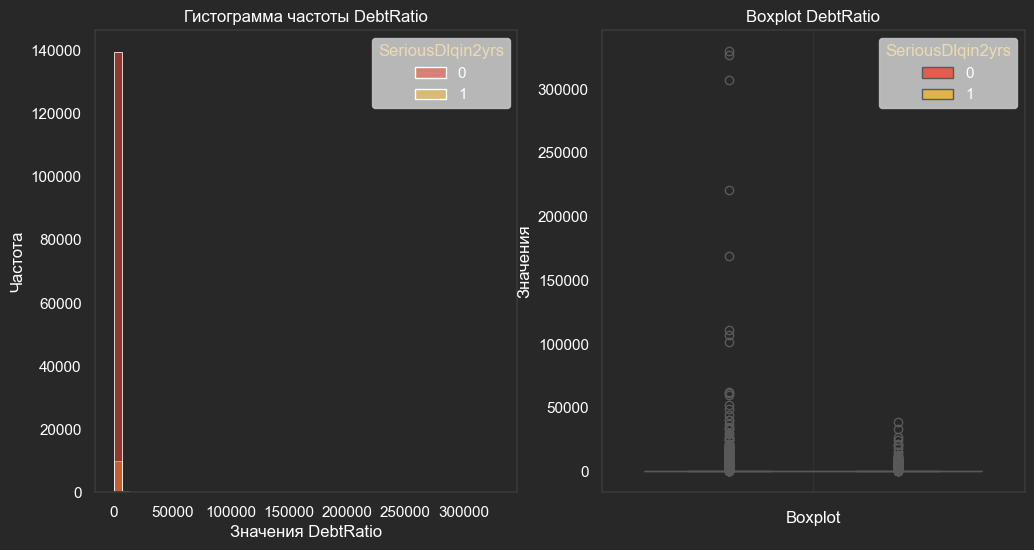

count    149999.000000
mean        353.007426
std        2037.825113
min           0.000000
25%           0.175074
50%           0.366503
75%           0.868257
max      329664.000000
Name: DebtRatio, dtype: float64

In [26]:
num_plot(df_train_proc, ['DebtRatio'], figsize=(12,6), target='SeriousDlqin2yrs', kde=False)
df_train_proc['DebtRatio'].describe()

Отношение платежей к доходу. Значения > 1 означают что человек платит по долгам больше чем зарабатывает. Максимум 329 664 - явная аномалия, скорее всего ошибка (возможно доход = 0). Медиана 0.37 при среднем 353 - экстремальный скос из-за выбросов.

In [27]:
high_debt = (df_train_proc['DebtRatio'] > 1).sum()
print(f'DebtRatio > 1: {high_debt} ({high_debt/len(df_train_proc)*100:.1f}%)')

DebtRatio > 1: 35137 (23.4%)


In [28]:
quantiles = [0.75,0.8,0.81,0.85,0.9,0.95,0.975,0.99]

for i in quantiles:
    print(i*100,'квантиль, значение Debtratio: ',df_train_proc['DebtRatio'].quantile(i))

75.0 квантиль, значение Debtratio:  0.8682570064999999
80.0 квантиль, значение Debtratio:  4.0
81.0 квантиль, значение Debtratio:  14.0
85.0 квантиль, значение Debtratio:  269.3000000000029
90.0 квантиль, значение Debtratio:  1267.0
95.0 квантиль, значение Debtratio:  2449.0
97.5 квантиль, значение Debtratio:  3489.0499999999884
99.0 квантиль, значение Debtratio:  4979.079999999958


In [29]:
df_train_proc[
    (df_train_proc["DebtRatio"] > df_train_proc["DebtRatio"].quantile(0.95)) &
    (df_train_proc['SeriousDlqin2yrs'] == df_train_proc['MonthlyIncome'])]

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,util_over_limit,util_bin,age_bin,is_retired
50,0,0.818978,73,0,3095.0,0.0,9,0,1,1,0.0,0,very_high,65+,1
73,0,0.059669,31,0,3162.0,0.0,11,0,2,0,1.0,0,low,25-35,0
90,0,0.039388,51,0,15466.0,0.0,7,0,0,0,0.0,0,low,45-55,0
326,0,0.013115,43,0,4211.0,0.0,21,0,2,0,2.0,0,very_low,35-45,0
508,0,1.000000,73,0,8500.0,0.0,2,0,0,0,0.0,0,very_high,65+,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
147523,0,0.666509,50,0,4351.0,0.0,12,0,2,0,2.0,0,high,45-55,0
148258,0,0.211955,31,0,2734.0,0.0,9,0,1,0,1.0,0,medium,25-35,0
148432,0,0.091785,37,0,2752.0,0.0,7,0,2,0,3.0,0,medium,35-45,0
149383,0,0.239302,63,0,3153.0,0.0,29,0,1,0,0.0,0,medium,55-65,0


Теория подтвердилась, из-за того что доход равен 0 или отсутствует полностью значение debt ratio оказалось экстремально высоким.

In [30]:
df_train_proc = df_train_proc[
    (df_train_proc["DebtRatio"] <= df_train_proc["DebtRatio"].quantile(0.95)) &
    (df_train_proc['MonthlyIncome'] > 1)
]
df_train_proc['DebtRatio'].describe()

count    118029.000000
mean          0.417278
std           2.757669
min           0.000000
25%           0.140999
50%           0.291183
75%           0.469928
max         450.333333
Name: DebtRatio, dtype: float64

#### MonthlyIncome

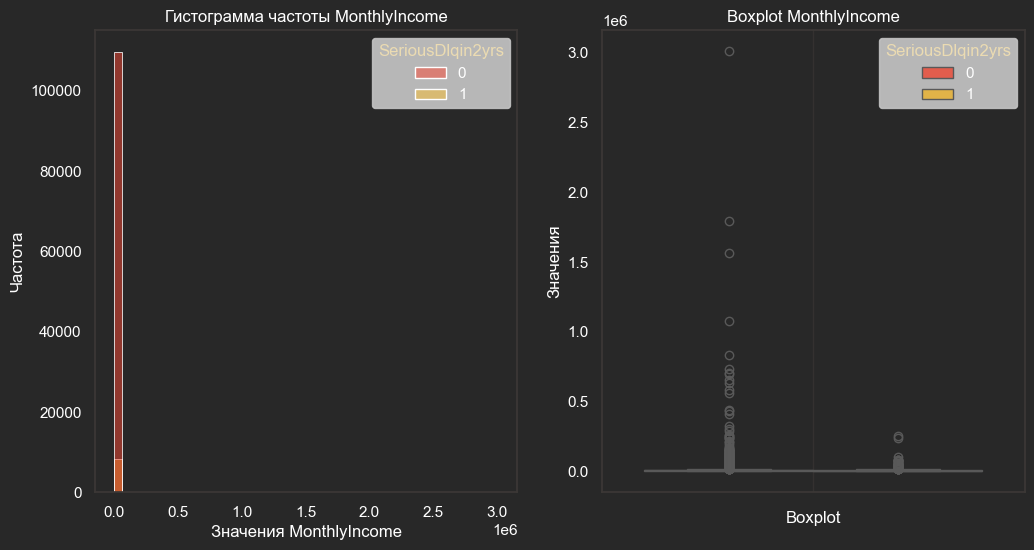

count    1.180290e+05
mean     6.796755e+03
std      1.449089e+04
min      2.000000e+00
25%      3.500000e+03
50%      5.478000e+03
75%      8.333000e+03
max      3.008750e+06
Name: MonthlyIncome, dtype: float64

In [31]:
num_plot(df_train_proc, ['MonthlyIncome'], figsize=(12,6), target='SeriousDlqin2yrs', kde=False)
df_train_proc['MonthlyIncome'].describe()

In [32]:
df_train_proc.isna().sum()

SeriousDlqin2yrs                        0
RevolvingUtilizationOfUnsecuredLines    0
age                                     0
NumberOfTime30-59DaysPastDueNotWorse    0
DebtRatio                               0
MonthlyIncome                           0
NumberOfOpenCreditLinesAndLoans         0
NumberOfTimes90DaysLate                 0
NumberRealEstateLoansOrLines            0
NumberOfTime60-89DaysPastDueNotWorse    0
NumberOfDependents                      0
util_over_limit                         0
util_bin                                0
age_bin                                 0
is_retired                              0
dtype: int64

Один из признаков с пропусками - 29731 пропусков (~20%).Медиана 5400, среднее 6670 - умеренный правый скос. Максимум 3 008 750 - экстремальный выброс, вероятно ошибка или исключительный случай, а также строки с зарплатой равной 0

In [33]:
df_train_proc['income_zero'] = (df_train_proc['MonthlyIncome'] < 1).astype(int)
print(df_train_proc.groupby('income_zero')['SeriousDlqin2yrs'].agg(['mean','count']))

                 mean   count
income_zero                  
0            0.070101  118029


Количество строк с нулевой заработной платой - 47 и все люди без зарплаты являются дефолтными

In [34]:
missing_rate = df_train_proc['MonthlyIncome'].isna().mean()
print(f'Пропуски MonthlyIncome: {missing_rate:.1%}')

Пропуски MonthlyIncome: 0.0%


In [35]:
df_train_proc['income_missing'] = df_train_proc['MonthlyIncome'].isna().astype(int)
print(df_train_proc.groupby('income_missing')['SeriousDlqin2yrs'].agg(['mean','count']))

                    mean   count
income_missing                  
0               0.070101  118029


In [36]:
df_train_proc['income_missing'].unique()

array([0])

Пропуск не является признаком отсутствия зарплаты и не несет риск дефолта

In [37]:
print(df_train_proc.groupby('age_bin')['MonthlyIncome'].median())

age_bin
<25      1800.0
25-35    3975.0
35-45    5725.0
45-55    6362.0
55-65    6250.0
65+      5000.0
Name: MonthlyIncome, dtype: float64


In [38]:
medians = df_train_proc.groupby('age_bin')['MonthlyIncome'].transform('median')
df_train_proc['MonthlyIncome'] = df_train_proc['MonthlyIncome'].fillna(medians)

#### NumberOfOpenCreditLinesAndLoans

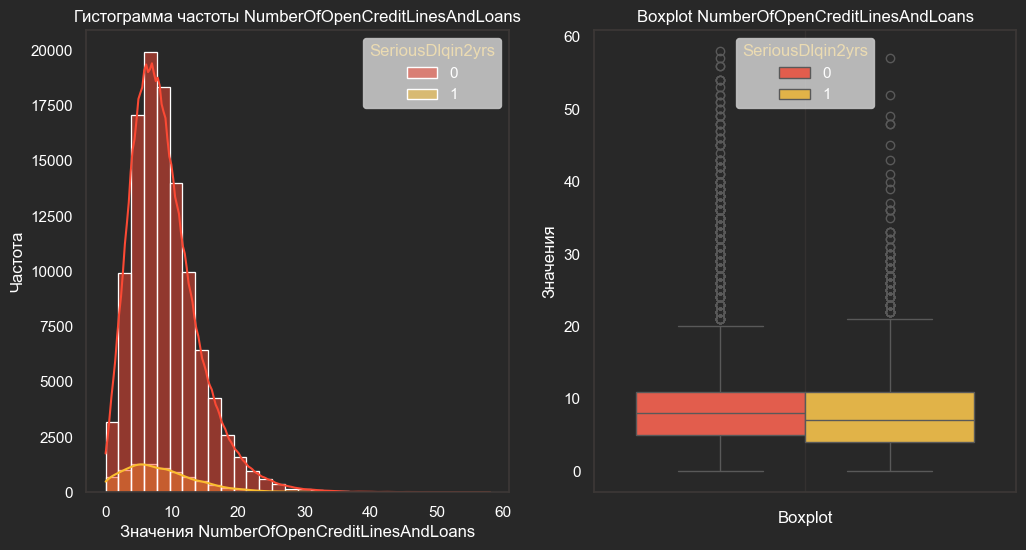

count    118029.000000
mean          8.788594
std           5.173624
min           0.000000
25%           5.000000
50%           8.000000
75%          11.000000
max          58.000000
Name: NumberOfOpenCreditLinesAndLoans, dtype: float64

In [39]:
num_plot(df_train_proc, ['NumberOfOpenCreditLinesAndLoans'], figsize=(12,6), target='SeriousDlqin2yrs', bins=30)
df_train_proc['NumberOfOpenCreditLinesAndLoans'].describe()

Пик около 8-9 кредитов,среднее 8.45, медиана 8. Максимум 58 - выброс. У класса 1 (дефолт) IQR шире и медиана чуть ниже - клиенты с дефолтом имеют немного меньше открытых кредитов. Это контринтуитивно: больше кредитов не значит выше риск и наоборот, многочисленные успешно обслуживаемые кредиты сигнализируют о надёжности заёмщика, возможно, особенность выборки

In [40]:
df_train_proc['zero_active_credits'] = (df_train_proc['NumberOfOpenCreditLinesAndLoans'] < 1).astype('int')
df_train_proc.groupby('zero_active_credits')['SeriousDlqin2yrs'].agg(['mean','count'])

,mean,count
zero_active_credits,,
0,0.068130,116909
1,0.275893,1120


Теперь понятно в чем дело, большинство дефолтных клиентов имеют закрытый долг по кредиту, поэтому дефолты сконцентрированы в левом хвосте гистограммы

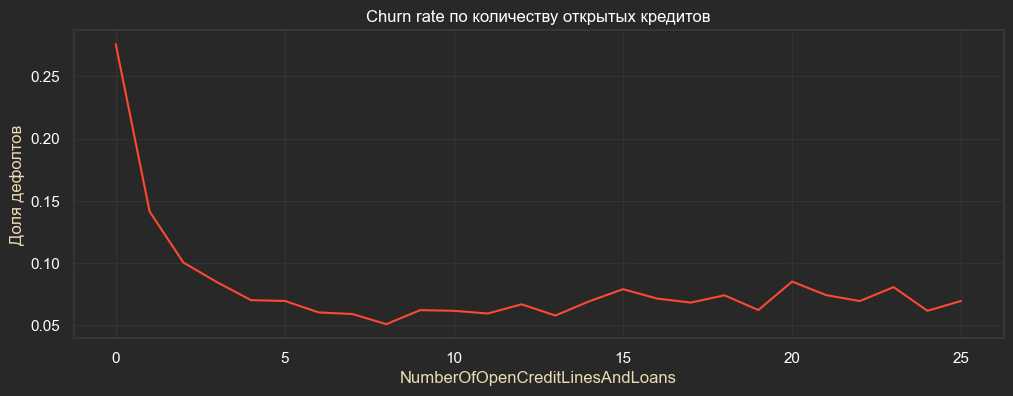

In [41]:
credit_churn = df_train_proc.groupby(
    df_train_proc['NumberOfOpenCreditLinesAndLoans'].clip(upper=25)
)['SeriousDlqin2yrs'].mean()

plt.figure(figsize=(12, 4))
sns.lineplot(x=credit_churn.index, y=credit_churn.values, color=colorbox[0])
plt.title('Churn rate по количеству открытых кредитов')
plt.xlabel('NumberOfOpenCreditLinesAndLoans')
plt.ylabel('Доля дефолтов')
plt.show()

#### NumberOfTimes90DaysLate и NumberOfTime60-89DaysPastDueNotWorse

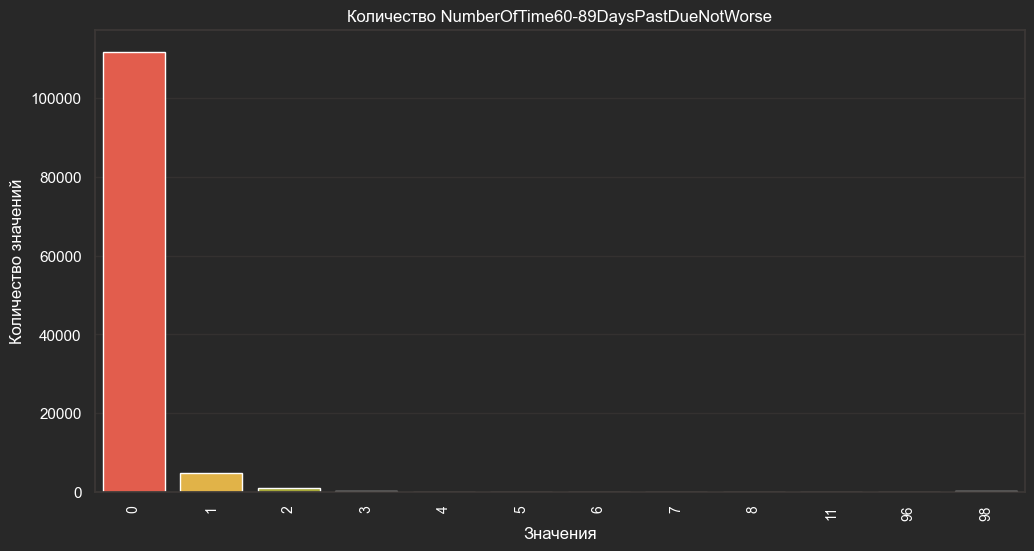

count    118029.000000
mean          0.183040
std           3.373665
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max          98.000000
Name: NumberOfTime60-89DaysPastDueNotWorse, dtype: float64

In [42]:
count_plot(df_train_proc, ['NumberOfTime60-89DaysPastDueNotWorse'], figsize=(12,6))
df_train_proc['NumberOfTime60-89DaysPastDueNotWorse'].describe()

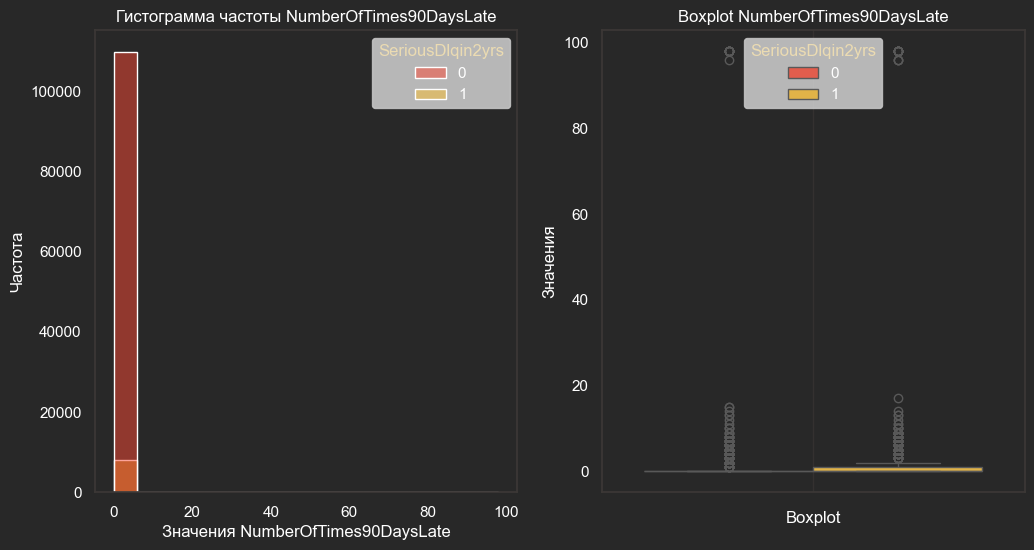

count    118029.000000
mean          0.207407
std           3.391633
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max          98.000000
Name: NumberOfTimes90DaysLate, dtype: float64

In [43]:
num_plot(df_train_proc, ['NumberOfTimes90DaysLate'], figsize=(12,6), target='SeriousDlqin2yrs', kde=False, bins=17)
df_train_proc['NumberOfTimes90DaysLate'].describe()

Все 3 признака (30-59, 60-89 и 90+ дней задержки платежа) сконцентрированы в нуле, 75% клиентов имеют 0 просрочек. Также, все три признака просрочек содержат аномальные значения 96 и 98

In [44]:
df_train_proc['is_anomaly'] = (
    (df_train_proc['NumberOfTime30-59DaysPastDueNotWorse'] > 90) |
    (df_train_proc['NumberOfTime60-89DaysPastDueNotWorse'] > 90) |
    (df_train_proc['NumberOfTimes90DaysLate'] > 90)
).astype(int)

df_train_proc.groupby('is_anomaly')['SeriousDlqin2yrs'].mean()

is_anomaly
0    0.069489
1    0.589928
Name: SeriousDlqin2yrs, dtype: float64

In [45]:
late_cols = [
    'NumberOfTime30-59DaysPastDueNotWorse',
    'NumberOfTime60-89DaysPastDueNotWorse',
    'NumberOfTimes90DaysLate'
]

for col in late_cols:
    max_value = df_train_proc.loc[df_train_proc[col] < 90, col].max()
    anomaly_count = df_train_proc[col].isin([96, 98]).sum()
    print(f'{col}: Кол-во аномальных значений: {anomaly_count}')
    df_train_proc[col] = df_train_proc[col].replace([96, 98], max_value)
    print(f"Максимальное значение после изменений: {df_train_proc[col].max()}")

NumberOfTime30-59DaysPastDueNotWorse: Кол-во аномальных значений: 139
Максимальное значение после изменений: 13
NumberOfTime60-89DaysPastDueNotWorse: Кол-во аномальных значений: 139
Максимальное значение после изменений: 11
NumberOfTimes90DaysLate: Кол-во аномальных значений: 139
Максимальное значение после изменений: 17


In [46]:
df_train_proc['total_late_payments'] = (
    df_train_proc['NumberOfTime30-59DaysPastDueNotWorse'] +
    df_train_proc['NumberOfTime60-89DaysPastDueNotWorse'] +
    df_train_proc['NumberOfTimes90DaysLate']
)
print(df_train_proc.groupby(df_train_proc['total_late_payments'].clip(upper=10))['SeriousDlqin2yrs'].agg(['mean','count']).round(3))

                      mean  count
total_late_payments              
0                    0.030  92924
1                    0.121  14253
2                    0.236   4981
3                    0.338   2390
4                    0.432   1314
5                    0.520    798
6                    0.593    491
7                    0.603    305
8                    0.583    163
9                    0.660    103
10                   0.635    307


#### NumberRealEstateLoansOrLines

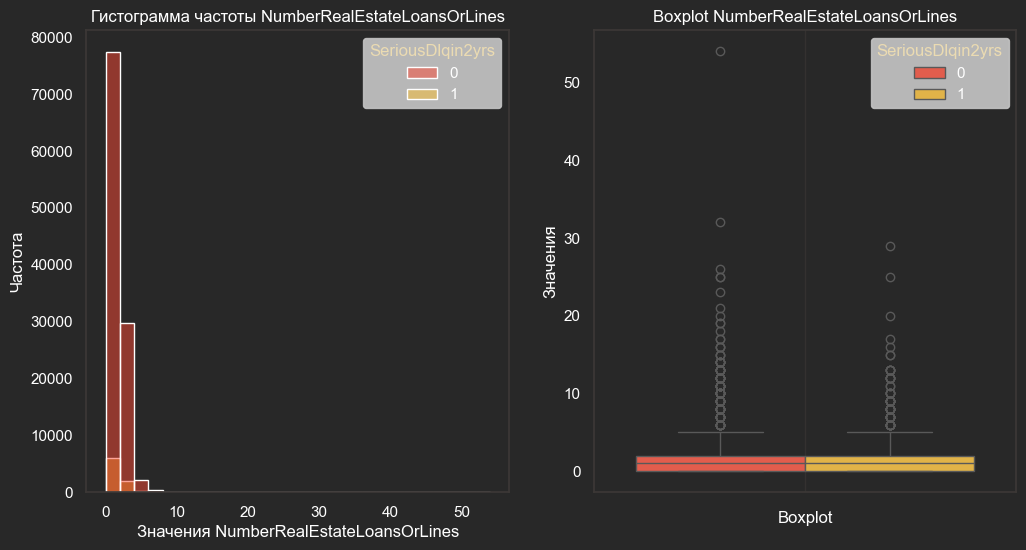

count    118029.000000
mean          1.060426
std           1.152557
min           0.000000
25%           0.000000
50%           1.000000
75%           2.000000
max          54.000000
Name: NumberRealEstateLoansOrLines, dtype: float64

In [47]:
num_plot(df_train_proc, ['NumberRealEstateLoansOrLines'], figsize=(12,6), target='SeriousDlqin2yrs', kde=False, bins=27)
df_train_proc['NumberRealEstateLoansOrLines'].describe()

Медиана 1, среднее 1.05 - большинство клиентов имеют 0-2 ипотечных кредита. Максимум 54 - аномальный выброс. Классы практически идентичны - признак слабо разделяет дефолтников от добросовестных заёмщиков в одиночку, но в комбинации с доходом может быть полезен.

#### NumberOfDependents

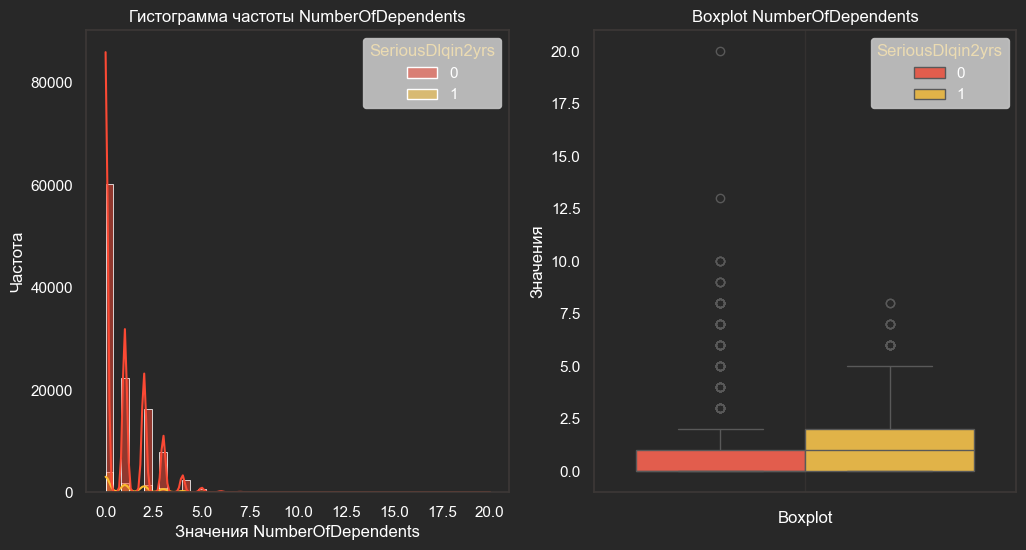

count    118029.000000
mean          0.853053
std           1.147401
min           0.000000
25%           0.000000
50%           0.000000
75%           2.000000
max          20.000000
Name: NumberOfDependents, dtype: float64

In [48]:
num_plot(df_train_proc, ['NumberOfDependents'], figsize=(12,6), target='SeriousDlqin2yrs')
df_train_proc['NumberOfDependents'].describe()

75% клиентов имеют 0-1 иждивенца, медиана 0. Максимум 20 - возможен. Боксплот выявляет интересный паттерн: у класса 1 (дефолт) медиана иждивенцев выше - больше иждивенцев коррелирует с риском просрочки. Это логично: больше иждивенцев следовательно выше расходы - меньше свободных средств для обслуживания долга.

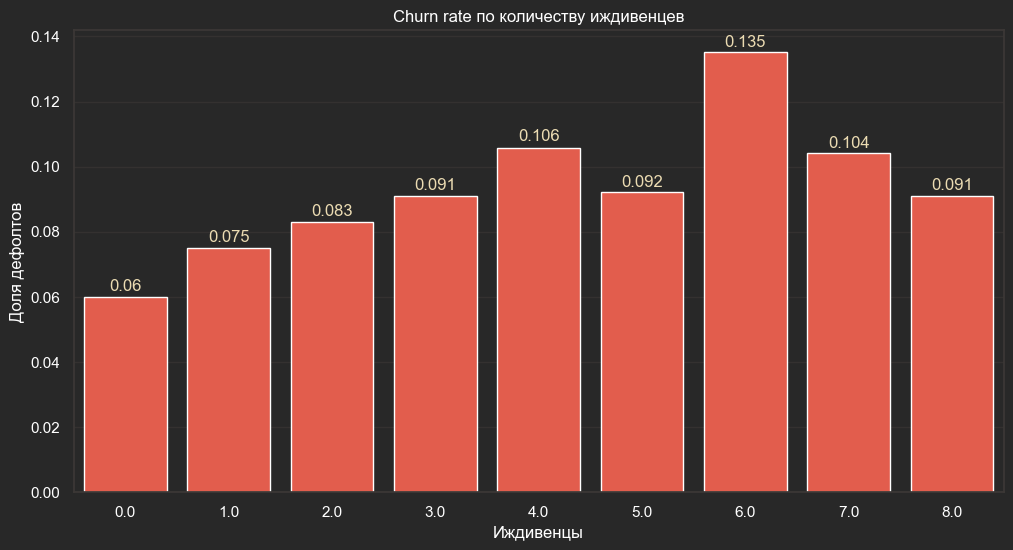

In [49]:
plt.figure(figsize=(12, 6))
sns.barplot(
    data=df_train_proc[df_train_proc['NumberOfDependents'] <= 8].groupby(
        'NumberOfDependents'
    )['SeriousDlqin2yrs'].mean().reset_index(),
    x='NumberOfDependents', y='SeriousDlqin2yrs', color=colorbox[0]
)
for i, v in enumerate(df_train_proc[df_train_proc['NumberOfDependents'] <= 8].groupby('NumberOfDependents')['SeriousDlqin2yrs'].mean().round(3).values):
    plt.text(i, v + 0.001, str(v), ha='center', va='bottom', fontsize=12)

plt.title('Churn rate по количеству иждивенцев', color='white')
plt.xlabel('Иждивенцы', color='white')
plt.ylabel('Доля дефолтов', color='white')
plt.show()

In [50]:
df_train_proc['income_per_dependent'] = (
    df_train_proc['MonthlyIncome'] /
    (df_train_proc['NumberOfDependents'] + 1)
)
print(df_train_proc.groupby('SeriousDlqin2yrs')['income_per_dependent'].median())

SeriousDlqin2yrs
0    3500.0
1    2600.0
Name: income_per_dependent, dtype: float64


Зарплата на члена семьи является важным показателем, у дефолтных клиентов она ниже на ~30%

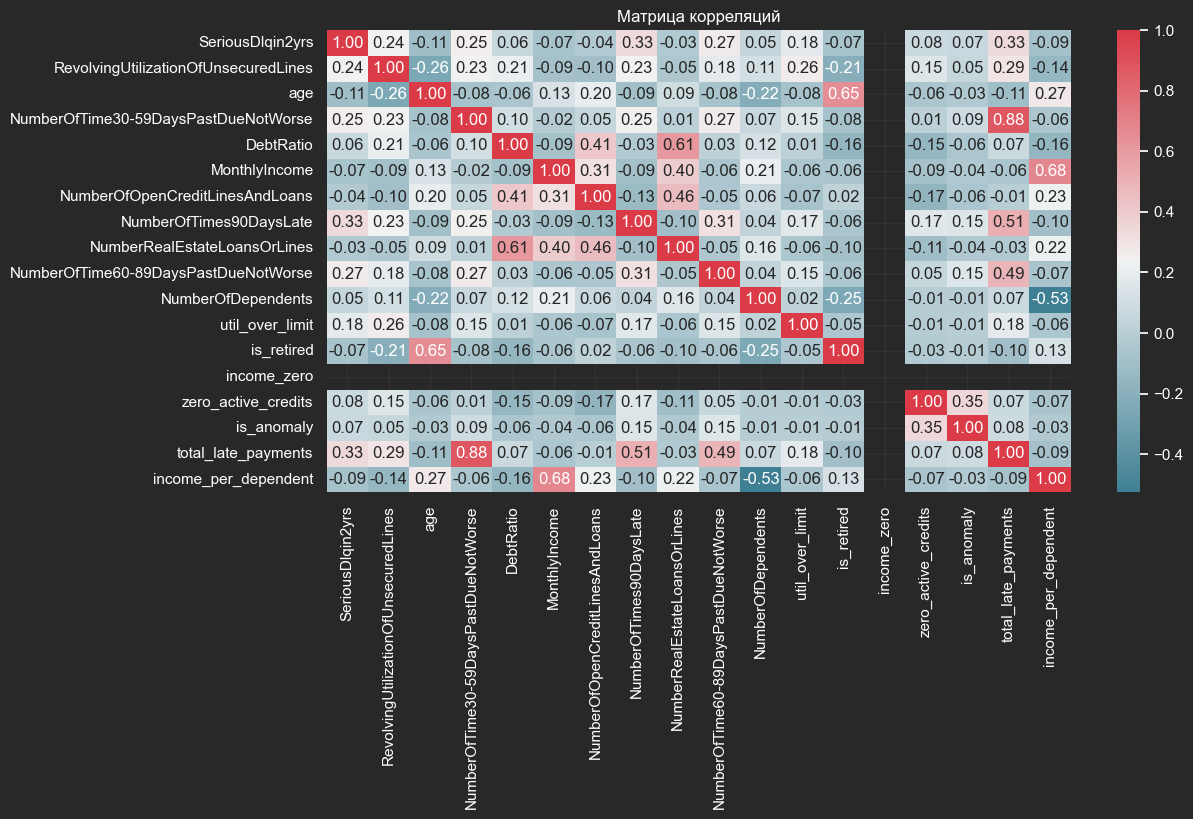

In [51]:
cat_col = df_train_proc.select_dtypes(['category', 'object']).columns.tolist()

plt.figure(figsize=(12,6))
sns.heatmap(
    df_train_proc.drop(['age_bin','util_bin','income_missing'], axis=1).corr(method='spearman'),
    cbar=True,
    cmap=colormap,
    annot=True,
    fmt='.2f'
)
plt.title("Матрица корреляций")
plt.show()

#### ML PART 1

In [52]:
df_train_proc.dtypes

SeriousDlqin2yrs                           int64
RevolvingUtilizationOfUnsecuredLines     float64
age                                        int64
NumberOfTime30-59DaysPastDueNotWorse       int64
DebtRatio                                float64
MonthlyIncome                            float64
NumberOfOpenCreditLinesAndLoans            int64
NumberOfTimes90DaysLate                    int64
NumberRealEstateLoansOrLines               int64
NumberOfTime60-89DaysPastDueNotWorse       int64
NumberOfDependents                       float64
util_over_limit                            int32
util_bin                                category
age_bin                                 category
is_retired                                 int32
income_zero                                int32
income_missing                             int32
zero_active_credits                        int32
is_anomaly                                 int32
total_late_payments                        int64
income_per_dependent

In [53]:
df_train_proc['util_bin'] = df_train_proc['util_bin'].astype(str)
df_train_proc['age_bin'] = df_train_proc['age_bin'].astype(str)

In [54]:
df_train_proc.info()

<class 'pandas.core.frame.DataFrame'>
Index: 118029 entries, 0 to 149999
Data columns (total 21 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      118029 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  118029 non-null  float64
 2   age                                   118029 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  118029 non-null  int64  
 4   DebtRatio                             118029 non-null  float64
 5   MonthlyIncome                         118029 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       118029 non-null  int64  
 7   NumberOfTimes90DaysLate               118029 non-null  int64  
 8   NumberRealEstateLoansOrLines          118029 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  118029 non-null  int64  
 10  NumberOfDependents                    118029 non-null  float64
 11  util_

In [55]:
print('Размер тренировочного датасета:', df_train_proc.shape)
print('Размер тестового датасета:', df_test_proc.shape)

Размер тренировочного датасета: (118029, 21)
Размер тестового датасета: (101503, 10)


In [56]:
X = df_train_proc.drop('SeriousDlqin2yrs', axis=1)
y = df_train_proc['SeriousDlqin2yrs']

In [57]:
X.drop(cat_col, axis=1, inplace=True)

In [58]:
cat_fi = CatBoostClassifier(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    auto_class_weights='Balanced',
    random_state=RANDOM_STATE,
    verbose=3,
)
cat_fi.fit(X, y)

0:	learn: 0.6714064	total: 182ms	remaining: 1m 30s
3:	learn: 0.6189606	total: 240ms	remaining: 29.8s
6:	learn: 0.5839261	total: 298ms	remaining: 21s
9:	learn: 0.5573804	total: 359ms	remaining: 17.6s
12:	learn: 0.5378101	total: 416ms	remaining: 15.6s
15:	learn: 0.5237354	total: 475ms	remaining: 14.4s
18:	learn: 0.5132358	total: 532ms	remaining: 13.5s
21:	learn: 0.5048719	total: 593ms	remaining: 12.9s
24:	learn: 0.4983714	total: 717ms	remaining: 13.6s
27:	learn: 0.4933899	total: 780ms	remaining: 13.1s
30:	learn: 0.4896159	total: 841ms	remaining: 12.7s
33:	learn: 0.4863895	total: 899ms	remaining: 12.3s
36:	learn: 0.4837632	total: 959ms	remaining: 12s
39:	learn: 0.4816919	total: 1.01s	remaining: 11.7s
42:	learn: 0.4797936	total: 1.08s	remaining: 11.5s
45:	learn: 0.4783168	total: 1.14s	remaining: 11.3s
48:	learn: 0.4771768	total: 1.2s	remaining: 11.1s
51:	learn: 0.4760719	total: 1.26s	remaining: 10.9s
54:	learn: 0.4750641	total: 1.32s	remaining: 10.7s
57:	learn: 0.4743784	total: 1.38s	remai

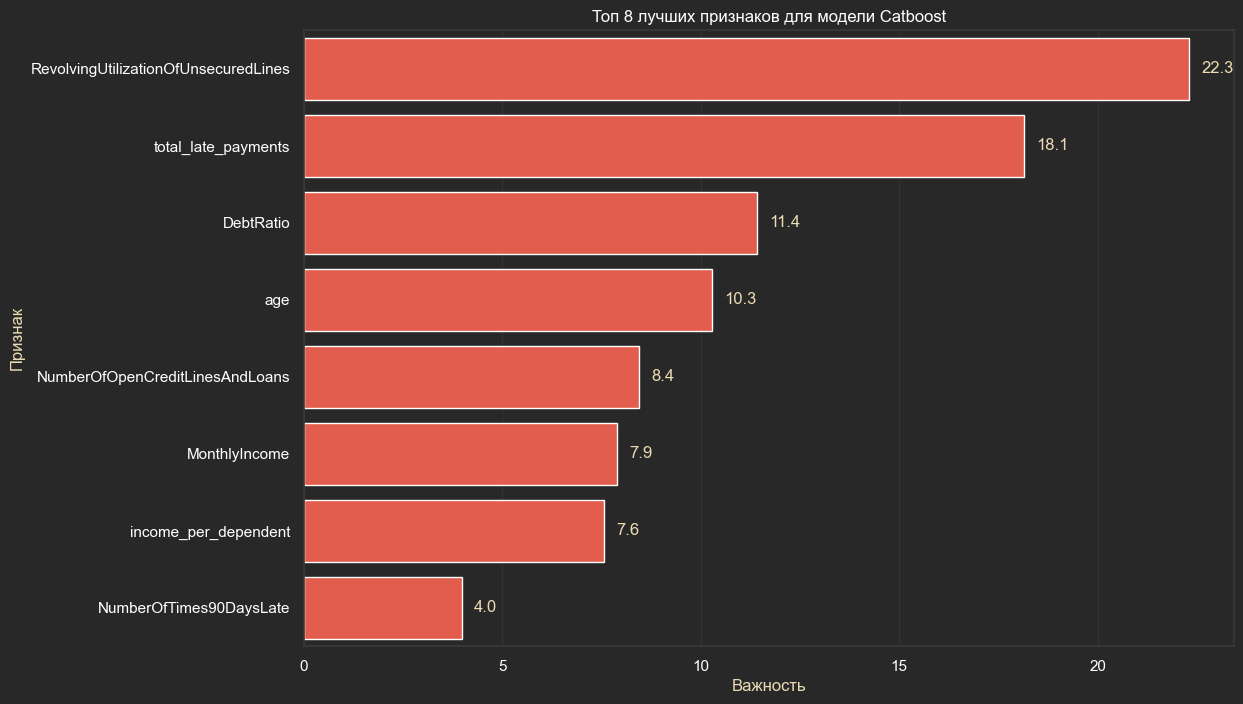

In [59]:
importances = cat_fi.feature_importances_
fi_cat_df = pd.DataFrame({
    'feature': X.columns,
    'importance': importances
}).sort_values('importance', ascending=False)

plt.figure(figsize=(12, 8))
sns.barplot(data=fi_cat_df.head(8), x='importance', y='feature', color=colorbox[0])
for i, v in enumerate(fi_cat_df.head(8)['importance']):
    plt.text(v + 0.3, i, f'{v:.1f}', ha='left', va='center', fontsize=12)
plt.title('Топ 8 лучших признаков для модели Catboost')
plt.xlabel('Важность')
plt.ylabel('Признак')
plt.tick_params()
plt.show()

FI подтверждает интуицию из EDA:
- RevolvingUtilization (19.9) и total_late_payments (17.6) - главные сигналы риска. Оба отражают платёжное поведение клиента, а не его демографию.
- DebtRatio (12.1) и age (11.6) - Долговая нагрузка и возраст дают структурный контекст и описание клиента
- NumberOfOpenCreditLines (8.7) и MonthlyIncome (7.9) Финансовые способности и история клиента.

### TOP FEATURES ML

#### preprocessing

In [60]:
TOP_FEATURES = [
    'RevolvingUtilizationOfUnsecuredLines',
    'total_late_payments',
    'DebtRatio',
    'age',
    'NumberOfOpenCreditLinesAndLoans',
    'MonthlyIncome',
    'income_per_dependent',
    'NumberOfTimes90DaysLate',
    'SeriousDlqin2yrs'
]

def make_fe(df):
    X = df.copy()
    X['total_late_payments'] = (
        X['NumberOfTime30-59DaysPastDueNotWorse'].clip(upper=10) +
        X['NumberOfTime60-89DaysPastDueNotWorse'].clip(upper=10) +
        X['NumberOfTimes90DaysLate'].clip(upper=10)
    ).astype(int)
    X['RevolvingUtilizationOfUnsecuredLines'] = (
        X['RevolvingUtilizationOfUnsecuredLines'].clip(upper=2)
    )
    X['DebtRatio'] = X['DebtRatio'].clip(upper=10)
    X['income_per_dependent'] = (X['MonthlyIncome'] / (X['NumberOfDependents'] + 1))
    X.dropna(subset=['MonthlyIncome'], axis=0, inplace=True)
    return X[TOP_FEATURES]

Создал функцию для предобработки и FE

In [61]:
train = make_fe(df_train)
X = train.drop('SeriousDlqin2yrs',axis=1)
y = train['SeriousDlqin2yrs']

test = make_fe(df_test)
X_test = test.drop('SeriousDlqin2yrs', axis=1)

In [62]:
train.head()

,RevolvingUtilizationOfUnsecuredLines,total_late_payments,DebtRatio,age,NumberOfOpenCreditLinesAndLoans,MonthlyIncome,income_per_dependent,NumberOfTimes90DaysLate,SeriousDlqin2yrs
0,0.766127,2,0.802982,45,13,9120.0,3040.0,0,1
1,0.957151,0,0.121876,40,4,2600.0,1300.0,0,0
2,0.658180,2,0.085113,38,2,3042.0,3042.0,1,0
3,0.233810,0,0.036050,30,5,3300.0,3300.0,0,0
4,0.907239,1,0.024926,49,7,63588.0,63588.0,0,0


In [63]:
train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 120269 entries, 0 to 149999
Data columns (total 9 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   RevolvingUtilizationOfUnsecuredLines  120269 non-null  float64
 1   total_late_payments                   120269 non-null  int32  
 2   DebtRatio                             120269 non-null  float64
 3   age                                   120269 non-null  int64  
 4   NumberOfOpenCreditLinesAndLoans       120269 non-null  int64  
 5   MonthlyIncome                         120269 non-null  float64
 6   income_per_dependent                  120269 non-null  float64
 7   NumberOfTimes90DaysLate               120269 non-null  int64  
 8   SeriousDlqin2yrs                      120269 non-null  int64  
dtypes: float64(4), int32(1), int64(4)
memory usage: 8.7 MB


In [64]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    random_state = RANDOM_STATE,
    test_size=VAL_SIZE,
    shuffle = True,
    stratify = y
)

print("Размер тренировочного датасета:", {X_train.shape})
print("Размер валидационного датасета:", {X_val.shape})
print("Размер тестового датасета:", {X_test.shape})
print("Таргет тренировочного датасета:", {y_train.shape})
print("Таргет валидационного датасета:", {y_val.shape})

Размер тренировочного датасета: {(102228, 8)}
Размер валидационного датасета: {(18041, 8)}
Размер тестового датасета: {(81400, 8)}
Таргет тренировочного датасета: {(102228,)}
Таргет валидационного датасета: {(18041,)}


Разбил данные на тренировочные, валидационные и тестовые сплиты

#### catboost v1

In [65]:
def objective_cat(trial):
    params = {
        'iterations':          trial.suggest_int('iterations', 500, 5000, step=100),
        'depth':               trial.suggest_int('depth', 3, 8),
        'learning_rate':       trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'l2_leaf_reg':         trial.suggest_float('l2_leaf_reg', 1, 10),
        'bagging_temperature': trial.suggest_float('bagging_temperature', 0, 1),
        'random_strength':     trial.suggest_float('random_strength', 1, 10),
        'min_data_in_leaf':    trial.suggest_int('min_data_in_leaf', 5, 50),
    }
    model = CatBoostClassifier(
        **params,
        auto_class_weights='Balanced',
        random_state=RANDOM_STATE,
        verbose=0
    )
    model.fit(X_train, y_train)
    return average_precision_score(y_val, model.predict_proba(X_val)[:, 1])

study_cat = optuna.create_study(direction='maximize')
study_cat.optimize(objective_cat, n_trials=30, show_progress_bar=True)

[I 2026-09-22 08:25:38,513] A new study created in memory with name: no-name-993389b2-fbb8-4c11-b533-0bed3686708c


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-09-22 08:27:41,809] Trial 0 finished with value: 0.3189887948422572 and parameters: {'iterations': 5000, 'depth': 8, 'learning_rate': 0.07024247958806241, 'l2_leaf_reg': 5.832575186502042, 'bagging_temperature': 0.11809119034381677, 'random_strength': 7.862159469360181, 'min_data_in_leaf': 27}. Best is trial 0 with value: 0.3189887948422572.
[I 2026-09-22 08:28:31,987] Trial 1 finished with value: 0.3567468079169122 and parameters: {'iterations': 3500, 'depth': 4, 'learning_rate': 0.14385937576010066, 'l2_leaf_reg': 8.550185130195779, 'bagging_temperature': 0.5887844609511457, 'random_strength': 9.853383929075937, 'min_data_in_leaf': 41}. Best is trial 1 with value: 0.3567468079169122.
[I 2026-09-22 08:28:39,054] Trial 2 finished with value: 0.3938999877494599 and parameters: {'iterations': 500, 'depth': 4, 'learning_rate': 0.0705304965608003, 'l2_leaf_reg': 3.898082432058227, 'bagging_temperature': 0.714779649724024, 'random_strength': 8.251959666566723, 'min_data_in_leaf': 44

In [66]:
best_params_cat = study_cat.best_params
print('CatBoost лучшие параметры:', best_params_cat)
print('CatBoost лучший ROC-AUC:', study_cat.best_value)

CatBoost лучшие параметры: {'iterations': 1800, 'depth': 5, 'learning_rate': 0.010342444080682073, 'l2_leaf_reg': 7.604758281536649, 'bagging_temperature': 0.6023127647496189, 'random_strength': 2.90072617082988, 'min_data_in_leaf': 21}
CatBoost лучший ROC-AUC: 0.3962152562375566


In [67]:
best_cat = CatBoostClassifier(
    **best_params_cat,
    auto_class_weights='Balanced',
    random_state=RANDOM_STATE,
    verbose=0
)
best_cat.fit(X_train, y_train)
y_pred_cat   = best_cat.predict(X_val)
y_proba_cat  = best_cat.predict_proba(X_val)[:, 1]

print('\nМетрики CatBoost на валидационных данных:')
model_metrics(y_val, y_pred_cat, y_proba_cat)


Метрики CatBoost на валидационных данных:
ROC-AUC : 0.8534
PR-AUC  : 0.3962
Gini    : 0.7068
Lift@10 : 5.3033
Lift@20 : 3.5648
Recall  : 0.7536
Precision  : 0.2194
F1  : 0.3398
Accuracy  : 0.7965


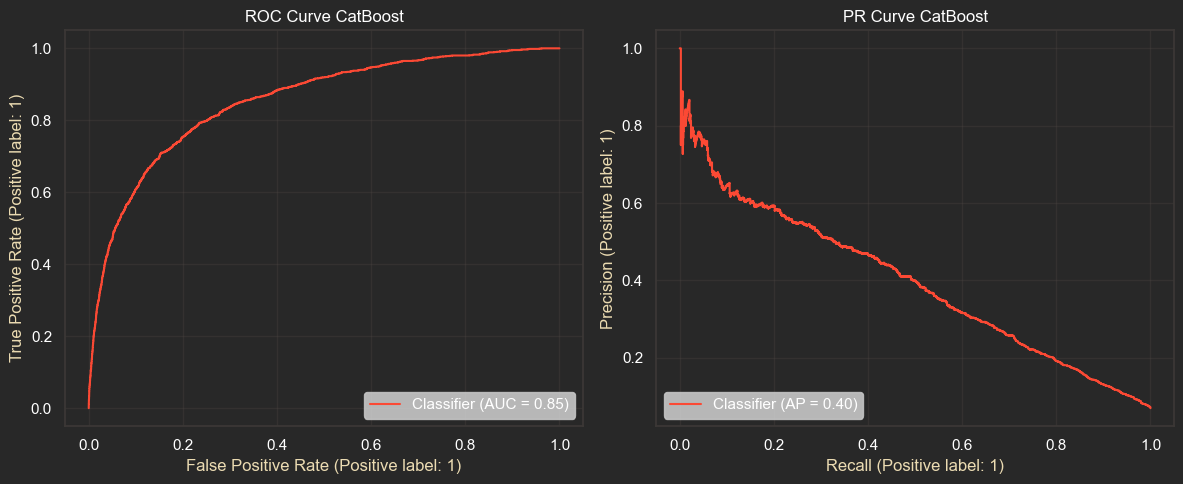

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
RocCurveDisplay.from_predictions(y_val, y_proba_cat, ax=axes[0])
axes[0].set_title('ROC Curve CatBoost')
PrecisionRecallDisplay.from_predictions(y_val, y_proba_cat, ax=axes[1])
axes[1].set_title('PR Curve CatBoost')
plt.tight_layout()
plt.show()

In [69]:
threshold_report(y_val, y_proba_cat)

Threshold  F1         Recall     Precision 
0.50      0.340     0.754     0.219     
0.40      0.290     0.830     0.176     
0.30      0.246     0.880     0.143     
0.20      0.206     0.930     0.116     
0.10      0.155     0.980     0.084     


#### lightgbm v1

In [70]:
def objective_lgb(trial):
    params = {
        'n_estimators':      trial.suggest_int('n_estimators', 300, 5000, step=100),
        'max_depth':         trial.suggest_int('max_depth', 3, 10),
        'learning_rate':     trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'num_leaves':        trial.suggest_int('num_leaves', 8, 100),
        'min_child_samples': trial.suggest_int('min_child_samples', 10, 200),
        'subsample':         trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree':  trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'reg_alpha':         trial.suggest_float('reg_alpha', 0, 10),
        'reg_lambda':        trial.suggest_float('reg_lambda', 0, 10),
    }
    model = LGBMClassifier(
        **params,
        class_weight='balanced',
        random_state=RANDOM_STATE,
        verbose=-1
    )
    model.fit(X_train, y_train)
    return average_precision_score(y_val, model.predict_proba(X_val)[:, 1])

study_lgb = optuna.create_study(direction='maximize')
study_lgb.optimize(objective_lgb, n_trials=30, show_progress_bar=True)

[I 2026-09-22 08:44:03,741] A new study created in memory with name: no-name-e73aa8d4-bdac-4dff-b241-202a03098623


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-09-22 08:44:18,075] Trial 0 finished with value: 0.37970338906349044 and parameters: {'n_estimators': 3100, 'max_depth': 6, 'learning_rate': 0.019543654932254288, 'num_leaves': 30, 'min_child_samples': 83, 'subsample': 0.9374722012416865, 'colsample_bytree': 0.9574104344340295, 'reg_alpha': 7.2632601856532855, 'reg_lambda': 2.5118462294657586}. Best is trial 0 with value: 0.37970338906349044.
[I 2026-09-22 08:44:46,159] Trial 1 finished with value: 0.37469923198210675 and parameters: {'n_estimators': 4100, 'max_depth': 9, 'learning_rate': 0.013630010993857359, 'num_leaves': 80, 'min_child_samples': 16, 'subsample': 0.8775084537898323, 'colsample_bytree': 0.6181656133509105, 'reg_alpha': 7.154516476466438, 'reg_lambda': 2.784230414881055}. Best is trial 0 with value: 0.37970338906349044.
[I 2026-09-22 08:44:54,156] Trial 2 finished with value: 0.3958531165855475 and parameters: {'n_estimators': 1100, 'max_depth': 8, 'learning_rate': 0.010003011744035468, 'num_leaves': 91, 'min_c

In [71]:
best_params_lgb = study_lgb.best_params
print('LightGBM лучшие параметры:', best_params_lgb)
print('LightGBM лучший ROC-AUC:', study_lgb.best_value)

LightGBM лучшие параметры: {'n_estimators': 800, 'max_depth': 8, 'learning_rate': 0.010450280881700668, 'num_leaves': 91, 'min_child_samples': 145, 'subsample': 0.8017253045989843, 'colsample_bytree': 0.8085767522751576, 'reg_alpha': 3.1912141479927643, 'reg_lambda': 5.958938314730571}
LightGBM лучший ROC-AUC: 0.3964468234619004


In [72]:
best_lgb = LGBMClassifier(
    **best_params_lgb,
    class_weight='balanced',
    random_state=RANDOM_STATE,
    verbose=-1
)
best_lgb.fit(X_train, y_train)
y_pred_lgb  = best_lgb.predict(X_val)
y_proba_lgb = best_lgb.predict_proba(X_val)[:, 1]

print('\nМетрики LightGBM на валидационных данных:')
model_metrics(y_val, y_pred_lgb, y_proba_lgb)


Метрики LightGBM на валидационных данных:
ROC-AUC : 0.8515
PR-AUC  : 0.3964
Gini    : 0.7029
Lift@10 : 5.2874
Lift@20 : 3.5369
Recall  : 0.7225
Precision  : 0.2294
F1  : 0.3482
Accuracy  : 0.8120


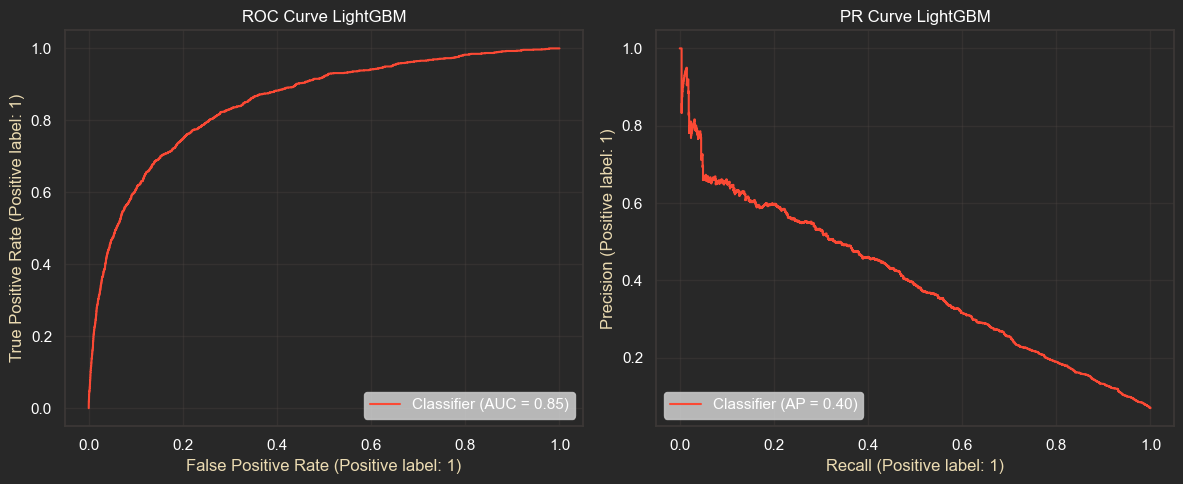

In [73]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
RocCurveDisplay.from_predictions(y_val, y_proba_lgb, ax=axes[0])
axes[0].set_title('ROC Curve LightGBM')
PrecisionRecallDisplay.from_predictions(y_val, y_proba_lgb, ax=axes[1])
axes[1].set_title('PR Curve LightGBM')
plt.tight_layout()
plt.show()

In [74]:
threshold_report(y_val, y_proba_lgb)

Threshold  F1         Recall     Precision 
0.50      0.348     0.722     0.229     
0.40      0.306     0.802     0.189     
0.30      0.260     0.870     0.153     
0.20      0.214     0.923     0.121     
0.10      0.164     0.970     0.089     


#### xgboost v1

In [75]:
def objective_xgb(trial):
    params = {
        'n_estimators':     trial.suggest_int('n_estimators', 300, 5000, step=100),
        'max_depth':        trial.suggest_int('max_depth', 3, 10),
        'learning_rate':    trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample':        trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 5, 50),
        'reg_alpha':        trial.suggest_float('reg_alpha', 0, 5),
        'reg_lambda':       trial.suggest_float('reg_lambda', 0, 5),
        'gamma':            trial.suggest_float('gamma', 0, 3),
    }
    model = XGBClassifier(
        **params,
        eval_metric='aucpr',
        random_state=RANDOM_STATE,
        verbosity=0
    )
    model.fit(X_train, y_train)
    return average_precision_score(y_val, model.predict_proba(X_val)[:, 1])

study_xgb = optuna.create_study(direction='maximize')
study_xgb.optimize(objective_xgb, n_trials=30, show_progress_bar=True)

[I 2026-09-22 08:48:56,914] A new study created in memory with name: no-name-8210e173-f45f-4217-ba69-9f7506baa2e3


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-09-22 08:49:05,727] Trial 0 finished with value: 0.38632076160650325 and parameters: {'n_estimators': 1500, 'max_depth': 8, 'learning_rate': 0.02516884365404274, 'subsample': 0.7960805841585273, 'colsample_bytree': 0.7511844191784679, 'min_child_weight': 50, 'reg_alpha': 4.397205344265275, 'reg_lambda': 3.845976353583143, 'gamma': 0.7475503961950157}. Best is trial 0 with value: 0.38632076160650325.
[I 2026-09-22 08:49:16,336] Trial 1 finished with value: 0.38239218339491543 and parameters: {'n_estimators': 1600, 'max_depth': 10, 'learning_rate': 0.021086803779946903, 'subsample': 0.6540593871279687, 'colsample_bytree': 0.7438778223874756, 'min_child_weight': 32, 'reg_alpha': 1.2196292522641854, 'reg_lambda': 4.989215852192105, 'gamma': 1.171732720956479}. Best is trial 0 with value: 0.38632076160650325.
[I 2026-09-22 08:49:20,949] Trial 2 finished with value: 0.3949711791218652 and parameters: {'n_estimators': 900, 'max_depth': 6, 'learning_rate': 0.018540476042806172, 'subsam

In [76]:
best_params_xgb = study_xgb.best_params
print('XGBoost лучшие параметры:', best_params_xgb)
print('XGBoost лучший ROC-AUC:', study_xgb.best_value)

XGBoost лучшие параметры: {'n_estimators': 300, 'max_depth': 7, 'learning_rate': 0.0348701076868201, 'subsample': 0.8188920623462582, 'colsample_bytree': 0.6835701379876035, 'min_child_weight': 23, 'reg_alpha': 3.67177393397639, 'reg_lambda': 3.4182672390419127, 'gamma': 2.607305870532101}
XGBoost лучший ROC-AUC: 0.3992908594786162


In [77]:
best_xgb = XGBClassifier(
    **best_params_xgb,
    eval_metric='aucpr',
    random_state=RANDOM_STATE,
    verbosity=0
)
best_xgb.fit(X_train, y_train)
y_pred_xgb  = best_xgb.predict(X_val)
y_proba_xgb = best_xgb.predict_proba(X_val)[:, 1]

print('\nМетрики XGBoost на валидационных данных:')
model_metrics(y_val, y_pred_xgb, y_proba_xgb)


Метрики XGBoost на валидационных данных:
ROC-AUC : 0.8533
PR-AUC  : 0.3993
Gini    : 0.7066
Lift@10 : 5.3352
Lift@20 : 3.5329
Recall  : 0.1954
Precision  : 0.5918
F1  : 0.2938
Accuracy  : 0.9347


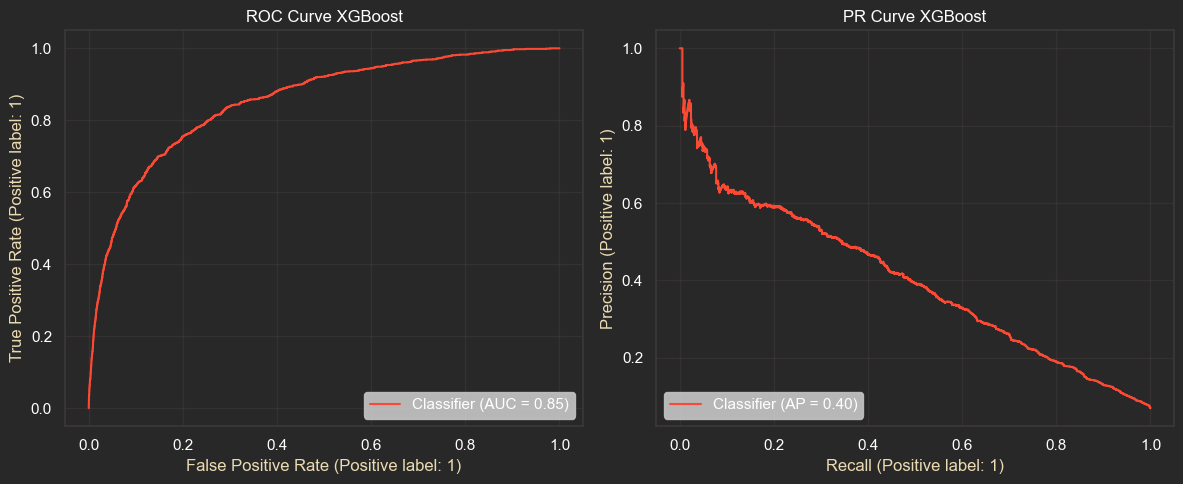

In [78]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
RocCurveDisplay.from_predictions(y_val, y_proba_xgb, ax=axes[0])
axes[0].set_title('ROC Curve XGBoost')
PrecisionRecallDisplay.from_predictions(y_val, y_proba_xgb, ax=axes[1])
axes[1].set_title('PR Curve XGBoost')
plt.tight_layout()
plt.show()

In [79]:
threshold_report(y_val, y_proba_xgb)

Threshold  F1         Recall     Precision 
0.50      0.294     0.195     0.592     
0.40      0.378     0.291     0.541     
0.30      0.428     0.388     0.477     
0.20      0.442     0.510     0.390     
0.10      0.391     0.672     0.275     


## Сравнение моделей

Все три модели показали сопоставимое качество ранжирования: ROC-AUC ~0.853, PR-AUC ~0.399, Lift@10 ~5.3. Разница между моделями статистически незначима и объясняется шумом валидационной выборки.

Финальная модель - LightGBM с лучшим PR-AUC (0.3984) и скоростью обучения.

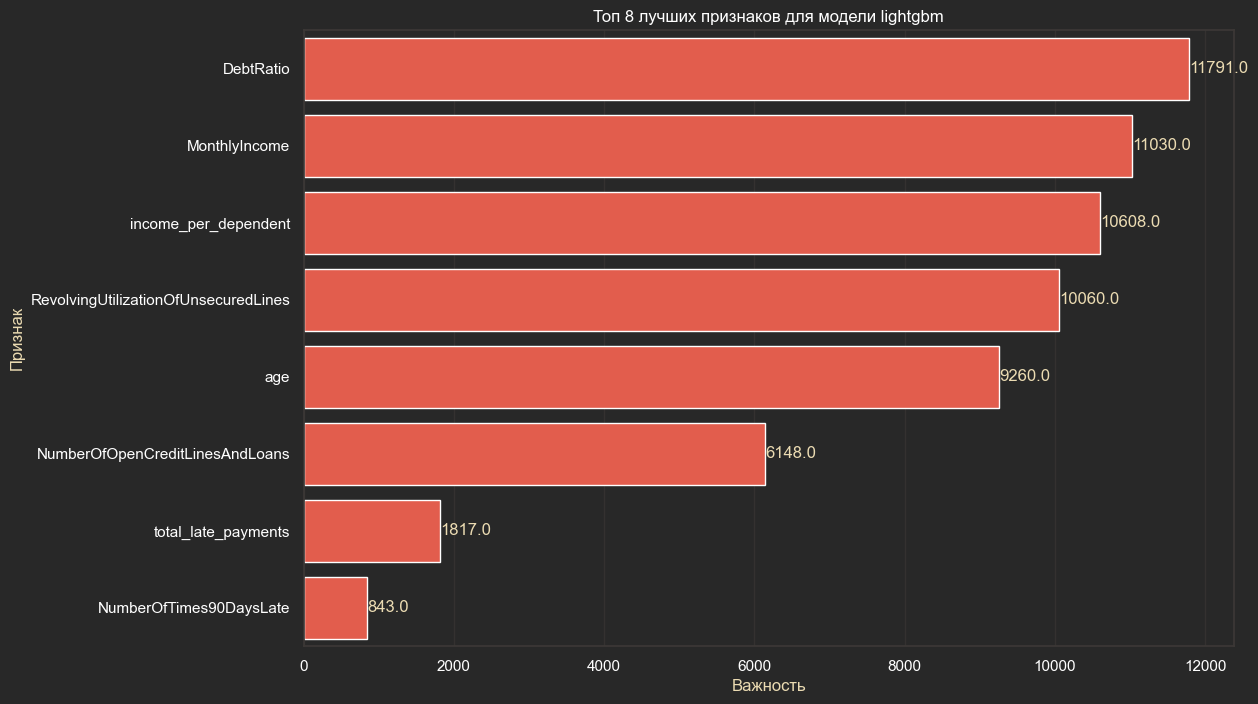

In [80]:
importances = best_lgb.feature_importances_
fi_lgb_df = pd.DataFrame({
    'feature': X_train.columns,
    'importance': importances
}).sort_values('importance', ascending=False)

plt.figure(figsize=(12, 8))
sns.barplot(data=fi_lgb_df.head(8), x='importance', y='feature', color=colorbox[0])
for i, v in enumerate(fi_lgb_df.head(8)['importance']):
    plt.text(v + 0.3, i, f'{v:.1f}', ha='left', va='center', fontsize=12)
plt.title('Топ 8 лучших признаков для модели lightgbm')
plt.xlabel('Важность')
plt.ylabel('Признак')
plt.tick_params()
plt.show()

* MonthlyIncome - самый важный фактор: уровень дохода клиента.
  
* RevolvingUtilizationOfUnsecuredLines - насколько активно клиент использует доступный кредитный лимит. Высокая загрузка лимита может быть сигналом финансовой нагрузки.
  
* DebtRatio - соотношение долговой нагрузки к доходу. Чем выше нагрузка, тем выше потенциальный кредитный риск.
  
* income_per_dependent - доход с учётом количества иждивенцев, то есть фактически показывает, сколько финансового ресурса приходится на одного члена семьи.
  
* Age - возраст клиента также заметно влияет на оценку риска.
  
* NumberOfOpenCreditLinesAndLoans - количество открытых кредитов и займов характеризует кредитную нагрузку клиента.
  
* total_late_payments и NumberOfTimes90DaysLate - история просрочек тоже важна, особенно длительные просрочки, но в этой модели они оказались менее значимыми, чем текущая финансовая картина клиента.

# Выгрузка модели

In [81]:
for col in X_train.columns:
    print(col,'\n')
    print(X_test[col].describe())
    print('_'* 50)

RevolvingUtilizationOfUnsecuredLines 

count    81400.000000
mean         0.336666
std          0.363318
min          0.000000
25%          0.035457
50%          0.177545
75%          0.585651
max          2.000000
Name: RevolvingUtilizationOfUnsecuredLines, dtype: float64
__________________________________________________
total_late_payments 

count    81400.000000
mean         0.463661
std          1.578055
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max         30.000000
Name: total_late_payments, dtype: float64
__________________________________________________
DebtRatio 

count    81400.000000
mean         0.528680
std          1.309241
min          0.000000
25%          0.141927
50%          0.294997
75%          0.481263
max         10.000000
Name: DebtRatio, dtype: float64
__________________________________________________
age 

count    81400.00000
mean        51.34726
std         14.40232
min         21.00000
25%         41.00000
50

In [82]:
joblib.dump(best_lgb, r'D:\Projects\GMSC\fastapi\model.pkl')

['D:\\Projects\\GMSC\\fastapi\\model.pkl']

In [88]:
train.to_csv(r'D:\Projects\GMSC\data\processed.csv')

#### _____ **Variable Name** _______________________ **Description** _____________________________________________________________________ **Type**

* **SeriousDlqin2yrs** - Была ли у человека просрочка на 90+ дней или хуже за последние 2 года	***integer (Y/N)***

* **RevolvingUtilizationOfUnsecuredLines** - Отношение общего баланса по кредитным картам и персональным кредитным линиям
(кроме недвижимости и автокредитов) к сумме кредитных лимитов	***float (percentage)***

* **age** - Возраст заёмщика ***integer***

* **NumberOfTime30-59DaysPastDueNotWorse** - Количество случаев, когда заёмщик имел просрочку 30–59 дней (не хуже) за последние 2 года ***integer***

* **DebtRatio** - Отношение ежемесячных платежей по долгам, алиментов и расходов на жизнь к ежемесячному валовому доходу	***float (percentage)***

* **MonthlyIncome** - Ежемесячный доход	***integer***

* **NumberOfOpenCreditLinesAndLoans** - Количество открытых кредитов (например, автокредит, ипотека) и кредитных линий (например, кредитные карты)	***integer***

* **NumberOfTimes90DaysLate** - Количество случаев просрочки на 90+ дней ***integer***

* **NumberRealEstateLoansOrLines** - Количество ипотечных кредитов и кредитов под недвижимость, включая кредитные линии под залог жилья ***integer***


* **NumberOfTime60-89DaysPastDueNotWorse** - Количество случаев, когда заёмщик имел просрочку 60–89 дней (не хуже) за последние 2 года ***integer***


* **NumberOfDependents** - Количество иждивенцев в семье (не включая самого заёмщика): супруг(а), дети и т.д.	***integer***